In [ ]:
import matplotlib.pyplot as plt

In [31]:
# Angelina
image_path = "../data/dataset/characters/images/test/ANG_16117401078905499179755929287133.labeled.jpg"
label_path = "../data/dataset/characters/labels/test/ANG_16117401078905499179755929287133.labeled.txt"

# DSBI
###

In [50]:
def get_class_label(class_id):
    return f"{class_id+1:06b}"[::-1]

def visualize_bbox(image_path, label_path):
    image = cv2.imread(image_path)

    height, width, _ = image.shape

    with open(label_path, "r") as f:
        for line in f:
            c, x_c_norm, y_c_norm, width_norm, height_norm = [float(x) for x in line.strip().split(" ")]

            x_c = (x_c_norm * width)
            y_c = (y_c_norm * height)
            w = (width_norm * width)
            h = (height_norm * height)

            x_min = x_c - w / 2
            y_min = y_c - h / 2
            x_max = x_c + w / 2
            y_max = y_c + h / 2

            cv2.rectangle(image, (round(x_min), round(y_min)), (round(x_max), round(y_max)), (0, 255, 0), 1)
            cv2.putText(image, f"{get_class_label(int(c))}", (round(x_min), round(y_min) - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.2, (0, 255, 0), 1)

    return image    

def show_image(img):
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(40, 30))
    plt.imshow(img_rgb)
    plt.axis("off")
    plt.show()

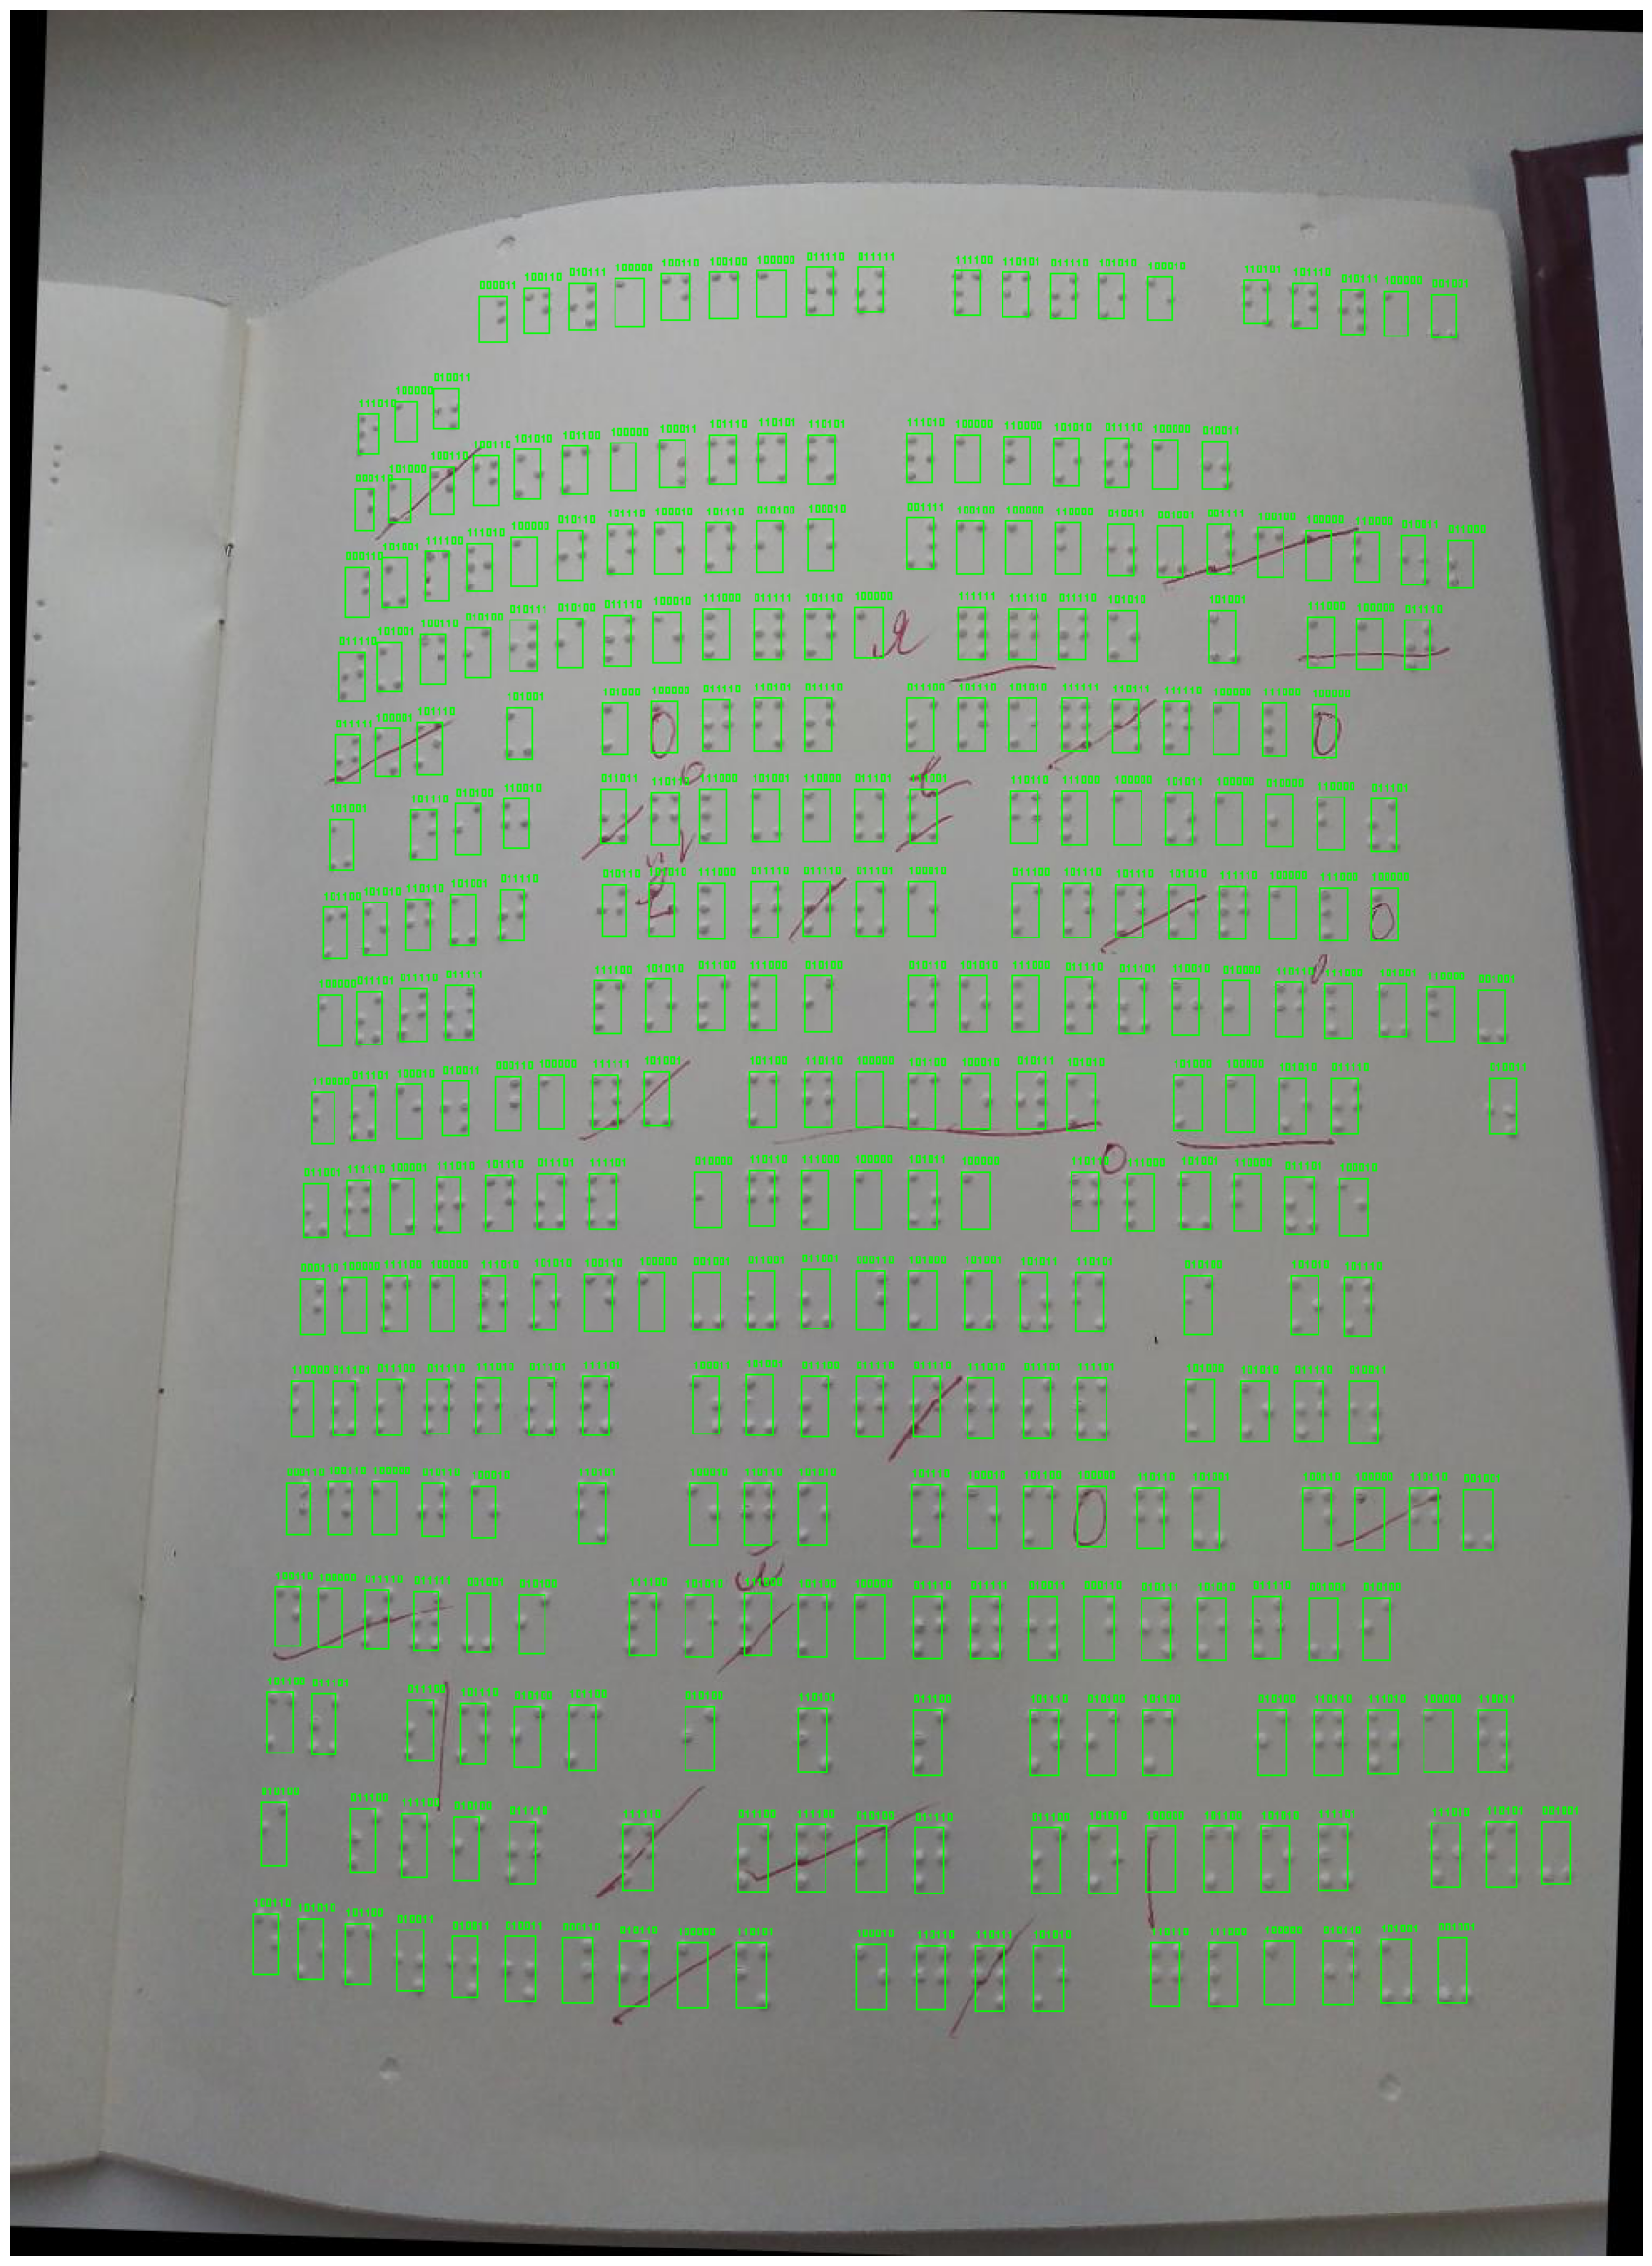

In [51]:
show_image(visualize_bbox(image_path, label_path))